**1.Implement and demonstrate the FIND-S algorithm for finding the most specific hypothesis based on a given set of training data samples.**

Most Specific Hypothesis:
['Sunny', 'Warm', '?', '?']


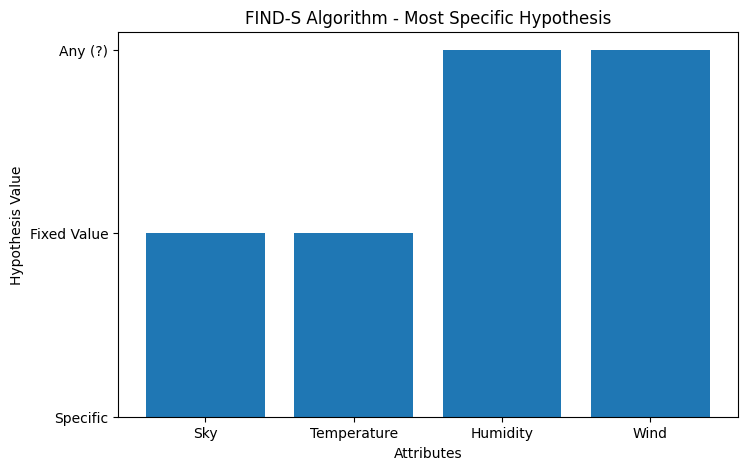

In [10]:
import matplotlib.pyplot as plt

# Training data
# [Sky, Temperature, Humidity, Wind, PlayTennis]
data = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Strong', 'No'],
    ['Sunny', 'Warm', 'High', 'Weak', 'Yes']
]

def find_s(data):
    hypothesis = ['0', '0', '0', '0']

    for row in data:
        if row[-1] == 'Yes':
            for i in range(len(hypothesis)):
                if hypothesis[i] == '0':
                    hypothesis[i] = row[i]
                elif hypothesis[i] != row[i]:
                    hypothesis[i] = '?'

    return hypothesis


hypothesis = find_s(data)

print("Most Specific Hypothesis:")
print(hypothesis)

# Graph
attributes = ['Sky', 'Temperature', 'Humidity', 'Wind']

# Convert hypothesis to numerical values for graph
values = []
for h in hypothesis:
    if h == '?':
        values.append(2)
    elif h == '0':
        values.append(0)
    else:
        values.append(1)

plt.figure(figsize=(8, 5))
plt.bar(attributes, values)

plt.title("FIND-S Algorithm - Most Specific Hypothesis")
plt.xlabel("Attributes")
plt.ylabel("Hypothesis Value")
plt.yticks([0, 1, 2], ['Specific', 'Fixed Value', 'Any (?)'])

plt.show()

**2. Candidate-Elimination Algorithm**

In [11]:
import pandas as pd

# Create the dataset directly in Google Colab
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'Temperature': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'PlayTennis': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Save as CSV file
df.to_csv('/content/trainingdata.csv', index=False)

print("Dataset created successfully!")
print(df)

Dataset created successfully!
     Sky Temperature Humidity    Wind PlayTennis
0  Sunny        Warm   Normal  Strong        Yes
1  Sunny        Warm     High  Strong        Yes
2  Rainy        Cold     High  Strong         No
3  Sunny        Warm     High    Weak        Yes


Training Data:
     Sky Temperature Humidity    Wind PlayTennis
0  Sunny        Warm   Normal  Strong        Yes
1  Sunny        Warm     High  Strong        Yes
2  Rainy        Cold     High  Strong         No
3  Sunny        Warm     High    Weak        Yes

Specific Boundary (S):
['Sunny', 'Warm', '?', '?']

General Boundary (G):
['Sunny', '?', '?', '?']
['?', 'Warm', '?', '?']


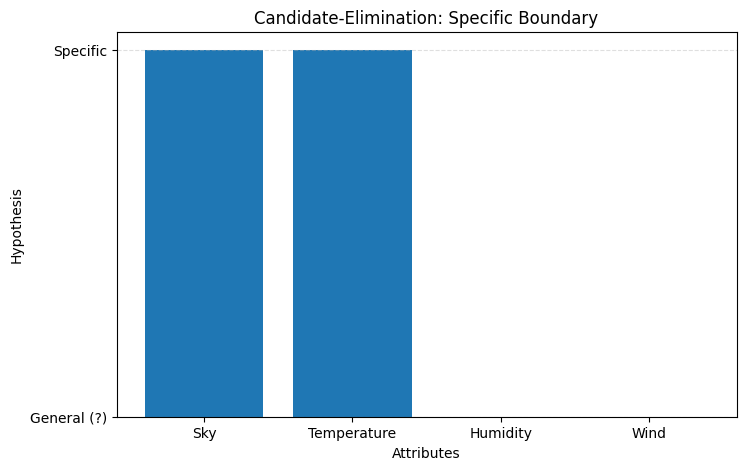

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Read CSV file
data = pd.read_csv('/content/trainingdata.csv')

attributes = list(data.columns[:-1])

print("Training Data:")
print(data)

# Initial boundaries
S = ['0'] * len(attributes)
G = [['?'] * len(attributes)]

for _, row in data.iterrows():
    example = list(row[:-1])
    target = row.iloc[-1]

    if target == 'Yes':
        # Update specific boundary
        for i in range(len(attributes)):
            if S[i] == '0':
                S[i] = example[i]
            elif S[i] != example[i]:
                S[i] = '?'

        # Keep consistent general hypotheses
        G = [
            g for g in G
            if all(g[i] == '?' or g[i] == example[i]
                   for i in range(len(attributes)))
        ]

    else:
        # Simplified general-boundary update
        new_G = []

        for g in G:
            for i in range(len(attributes)):
                if g[i] == '?' and S[i] not in ['0', '?']:
                    h = g.copy()
                    h[i] = S[i]

                    if h not in new_G:
                        new_G.append(h)

        G = [
            h for h in new_G
            if all(
                h[i] == '?' or h[i] != example[i]
                for i in range(len(attributes))
            )
        ]

print("\nSpecific Boundary (S):")
print(S)

print("\nGeneral Boundary (G):")
for g in G:
    print(g)

# Graph
values = [0 if x == '?' else 1 for x in S]

plt.figure(figsize=(8, 5))
plt.bar(attributes, values)
plt.title("Candidate-Elimination: Specific Boundary")
plt.xlabel("Attributes")
plt.ylabel("Hypothesis")
plt.yticks([0, 1], ['General (?)', 'Specific'])
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

**3. ID3 Decision Tree Algorithm**

New Sample Classification: NO


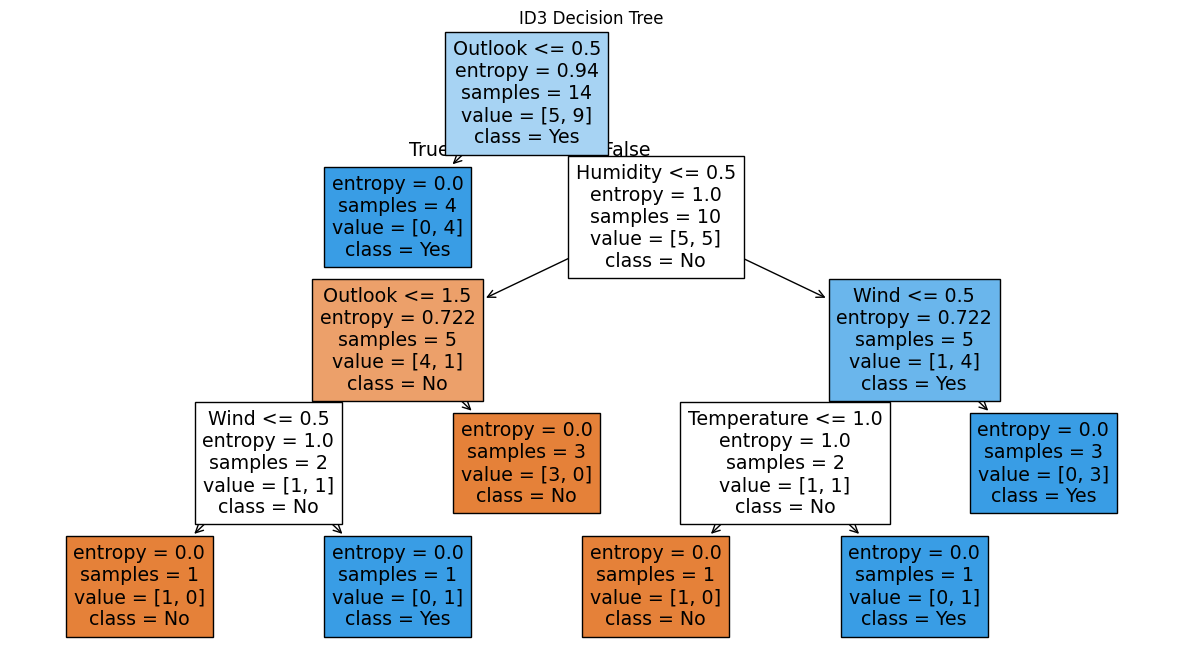

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder

# Dataset
data = pd.DataFrame({
    'Outlook': [
        'Sunny', 'Sunny', 'Overcast', 'Rain',
        'Rain', 'Rain', 'Overcast', 'Sunny',
        'Sunny', 'Rain', 'Sunny', 'Overcast',
        'Overcast', 'Rain'
    ],

    'Temperature': [
        'Hot', 'Hot', 'Hot', 'Mild',
        'Cool', 'Cool', 'Cool', 'Mild',
        'Cool', 'Mild', 'Mild', 'Mild',
        'Hot', 'Mild'
    ],

    'Humidity': [
        'High', 'High', 'High', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'High'
    ],

    'Wind': [
        'Weak', 'Strong', 'Weak', 'Weak',
        'Weak', 'Strong', 'Strong', 'Weak',
        'Weak', 'Weak', 'Strong', 'Strong',
        'Weak', 'Strong'
    ],

    'PlayTennis': [
        'No', 'No', 'Yes', 'Yes',
        'Yes', 'No', 'Yes', 'No',
        'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'No'
    ]
})

# Encode categorical data
X = data.drop('PlayTennis', axis=1)
y = data['PlayTennis']

encoder = LabelEncoder()

for column in X.columns:
    X[column] = encoder.fit_transform(X[column])

y = encoder.fit_transform(y)

# ID3 Decision Tree
model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X, y)

# New sample
new_sample = pd.DataFrame({
    'Outlook': ['Sunny'],
    'Temperature': ['Cool'],
    'Humidity': ['High'],
    'Wind': ['Strong']
})

# Encode new sample using the same mapping manually
mapping = {
    'Outlook': {'Overcast': 0, 'Rain': 1, 'Sunny': 2},
    'Temperature': {'Cool': 0, 'Hot': 1, 'Mild': 2},
    'Humidity': {'High': 0, 'Normal': 1},
    'Wind': {'Strong': 0, 'Weak': 1}
}

for column in new_sample.columns:
    new_sample[column] = new_sample[column].map(mapping[column])

prediction = model.predict(new_sample)

if prediction[0] == 1:
    print("New Sample Classification: YES")
else:
    print("New Sample Classification: NO")

# Plot decision tree
plt.figure(figsize=(15, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True
)

plt.title("ID3 Decision Tree")
plt.show()

**4. Artificial Neural Network using Backpropagation**

Predictions:
[0 0] => 0
[0 1] => 1
[1 0] => 1
[1 1] => 0


/tmp/ipykernel_837/1745595988.py:81: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  round(float(output[i]))


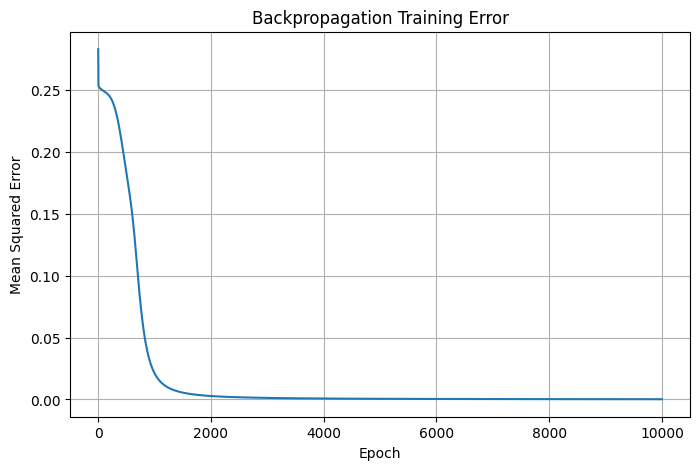

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# XOR dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])

# Sigmoid function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)


# Random weights
np.random.seed(42)

input_neurons = 2
hidden_neurons = 4
output_neurons = 1

W1 = np.random.randn(input_neurons, hidden_neurons)
b1 = np.zeros((1, hidden_neurons))

W2 = np.random.randn(hidden_neurons, output_neurons)
b2 = np.zeros((1, output_neurons))

learning_rate = 0.5

errors = []

# Backpropagation training
for epoch in range(10000):

    # Forward propagation
    hidden_input = np.dot(X, W1) + b1
    hidden_output = sigmoid(hidden_input)

    output_input = np.dot(hidden_output, W2) + b2
    output = sigmoid(output_input)

    # Error
    error = y - output
    mse = np.mean(error ** 2)

    errors.append(mse)

    # Backpropagation
    output_delta = error * sigmoid_derivative(output)

    hidden_error = np.dot(output_delta, W2.T)
    hidden_delta = hidden_error * sigmoid_derivative(hidden_output)

    # Update weights
    W2 += learning_rate * np.dot(hidden_output.T, output_delta)
    b2 += learning_rate * np.sum(output_delta, axis=0, keepdims=True)

    W1 += learning_rate * np.dot(X.T, hidden_delta)
    b1 += learning_rate * np.sum(hidden_delta, axis=0, keepdims=True)


# Test
print("Predictions:")

for i in range(len(X)):
    print(
        X[i],
        "=>",
        round(float(output[i]))
    )

# Graph
plt.figure(figsize=(8, 5))

plt.plot(errors)

plt.title("Backpropagation Training Error")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid()

plt.show()

**5. K-Nearest Neighbours (K-NN)**

Nearest Neighbors:
[[5 5]
 [3 3]
 [2 3]]

Predicted Class: 0


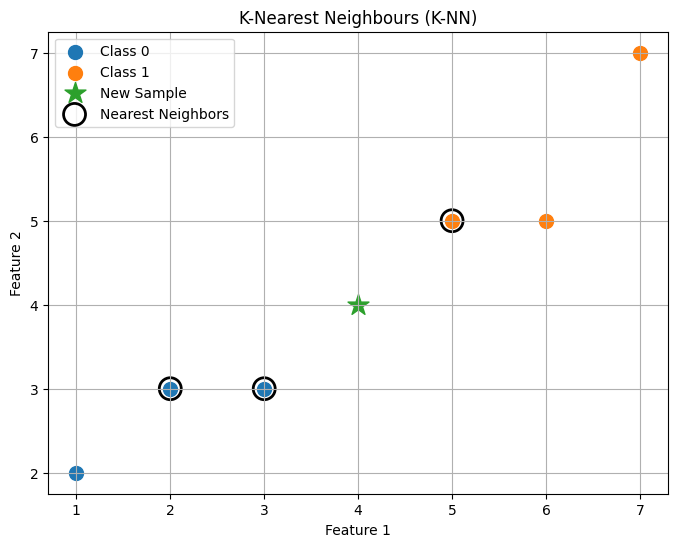

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Training data
X = np.array([
    [1, 2],
    [2, 3],
    [3, 3],
    [5, 5],
    [6, 5],
    [7, 7]
])

# Classes
y = np.array([
    0, 0, 0,
    1, 1, 1
])

# New sample
new_point = np.array([4, 4])

# K value
k = 3


# Calculate Euclidean distance
distances = []

for i in range(len(X)):
    distance = np.sqrt(np.sum((X[i] - new_point) ** 2))
    distances.append(distance)

# Get indices of nearest points
nearest_indices = np.argsort(distances)[:k]

# Get classes
nearest_classes = y[nearest_indices]

# Majority voting
prediction = np.bincount(nearest_classes).argmax()

print("Nearest Neighbors:")
print(X[nearest_indices])

print("\nPredicted Class:", prediction)


# Graph
plt.figure(figsize=(8, 6))

# Class 0
plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Class 0",
    s=100
)

# Class 1
plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class 1",
    s=100
)

# New point
plt.scatter(
    new_point[0],
    new_point[1],
    marker='*',
    s=250,
    label="New Sample"
)

# Highlight nearest neighbors
plt.scatter(
    X[nearest_indices, 0],
    X[nearest_indices, 1],
    facecolors='none',
    edgecolors='black',
    s=250,
    linewidths=2,
    label="Nearest Neighbors"
)

plt.title("K-Nearest Neighbours (K-NN)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid()

plt.show()

**6. Naïve Bayes Algorithm with Confusion Matrix and Accuracy**

Naive Bayes Accuracy: 91.11 %

Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



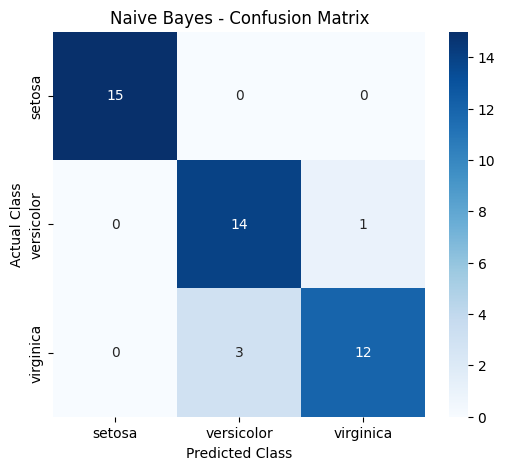

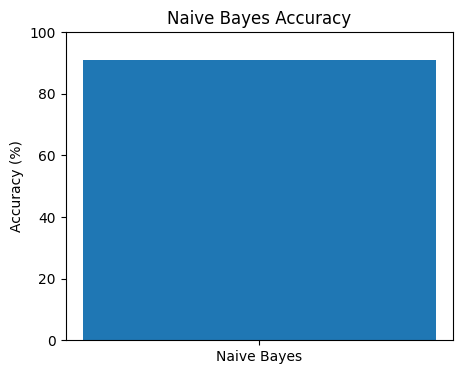

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Results
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Naive Bayes Accuracy:", round(accuracy * 100, 2), "%")
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

# Plot accuracy
plt.figure(figsize=(5, 4))
plt.bar(["Naive Bayes"], [accuracy * 100])
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Naive Bayes Accuracy")
plt.show()

**7. Logistic Regression Algorithm**

Logistic Regression Accuracy: 100.0 %

Confusion Matrix:
 [[15  0]
 [ 0 15]]


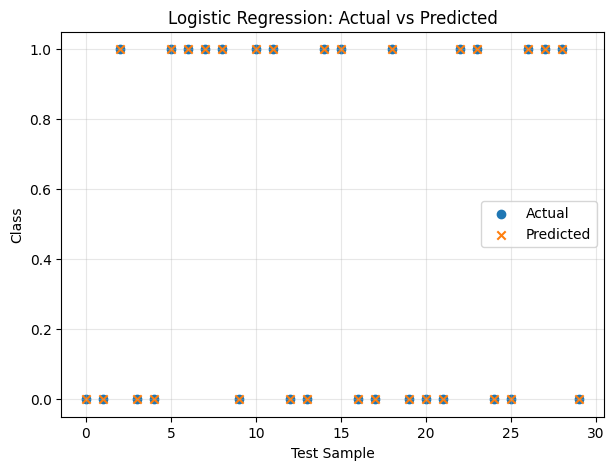

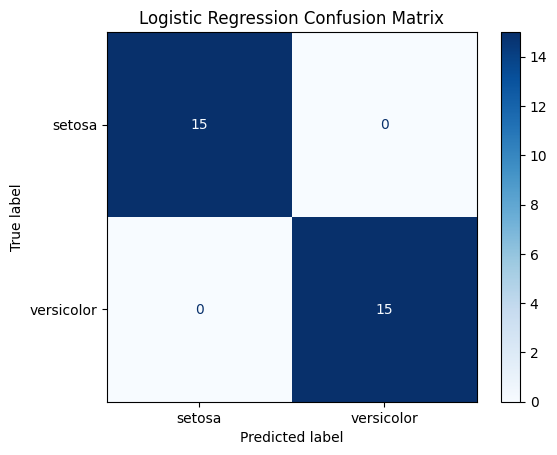

In [17]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load binary classification dataset
iris = load_iris()
X = iris.data[iris.target != 2, :2]
y = iris.target[iris.target != 2]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train Logistic Regression
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Graph 1: Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(range(len(y_test)), y_test, label="Actual", marker="o")
plt.scatter(range(len(y_pred)), y_pred, label="Predicted", marker="x")
plt.xlabel("Test Sample")
plt.ylabel("Class")
plt.title("Logistic Regression: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Graph 2: Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=iris.target_names[:2],
    cmap="Blues"
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

**8. Linear Regression Algorithm**

Slope: 0.025
Intercept: 2.5
R-squared: 1.0
Mean Squared Error: 0.0
Predicted price for 1000 sq.ft: 27.5 lakhs


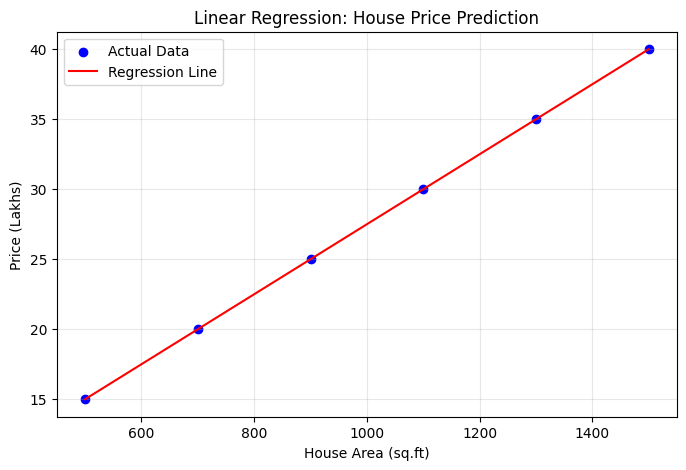

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Sample dataset: house area and price
# Area in square feet; price in lakhs
X = np.array([500, 700, 900, 1100, 1300, 1500]).reshape(-1, 1)
y = np.array([15, 20, 25, 30, 35, 40])

# Train model
model = LinearRegression()
model.fit(X, y)

# Predict
y_pred = model.predict(X)

print("Slope:", round(model.coef_[0], 4))
print("Intercept:", round(model.intercept_, 4))
print("R-squared:", round(r2_score(y, y_pred), 4))
print("Mean Squared Error:", round(mean_squared_error(y, y_pred), 4))

area = np.array([[1000]])
print("Predicted price for 1000 sq.ft:",
      round(model.predict(area)[0], 2), "lakhs")

# Graph
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, y_pred, color="red", label="Regression Line")
plt.xlabel("House Area (sq.ft)")
plt.ylabel("Price (Lakhs)")
plt.title("Linear Regression: House Price Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**9. Compare Linear and Polynomial Regression**

Linear Regression
MSE: 52.8
R2 Score: 0.9498

Polynomial Regression
MSE: 0.0
R2 Score: 1.0


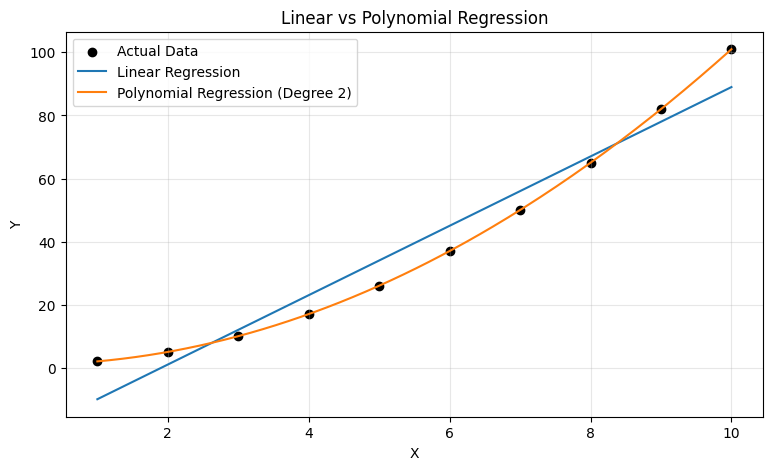

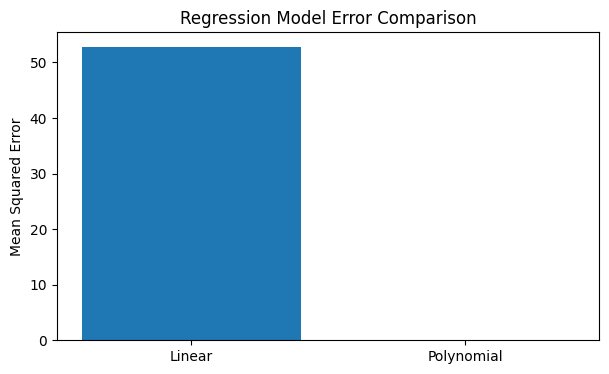

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Sample nonlinear dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([2, 5, 10, 17, 26, 37, 50, 65, 82, 101])

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X, y)
linear_pred = linear_model.predict(X)

# Polynomial Regression (degree 2)
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly_model.fit(X, y)
poly_pred = poly_model.predict(X)

# Evaluation
print("Linear Regression")
print("MSE:", round(mean_squared_error(y, linear_pred), 4))
print("R2 Score:", round(r2_score(y, linear_pred), 4))

print("\nPolynomial Regression")
print("MSE:", round(mean_squared_error(y, poly_pred), 4))
print("R2 Score:", round(r2_score(y, poly_pred), 4))

# Smooth curves
X_curve = np.linspace(1, 10, 200).reshape(-1, 1)

plt.figure(figsize=(9, 5))
plt.scatter(X, y, color="black", label="Actual Data")
plt.plot(X_curve, linear_model.predict(X_curve),
         label="Linear Regression")
plt.plot(X_curve, poly_model.predict(X_curve),
         label="Polynomial Regression (Degree 2)")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Compare MSE
mse_values = [
    mean_squared_error(y, linear_pred),
    mean_squared_error(y, poly_pred)
]

plt.figure(figsize=(7, 4))
plt.bar(["Linear", "Polynomial"], mse_values)
plt.ylabel("Mean Squared Error")
plt.title("Regression Model Error Comparison")
plt.show()

**10. Expectation-Maximization (EM) Algorithm**

EM Algorithm: Gaussian Mixture Model
Number of clusters: 3
Converged: True
Number of iterations: 2
Means of clusters:
 [[-2.65803969  9.04942651]
 [-6.88472071 -7.00475906]
 [ 4.76854828  2.01807919]]


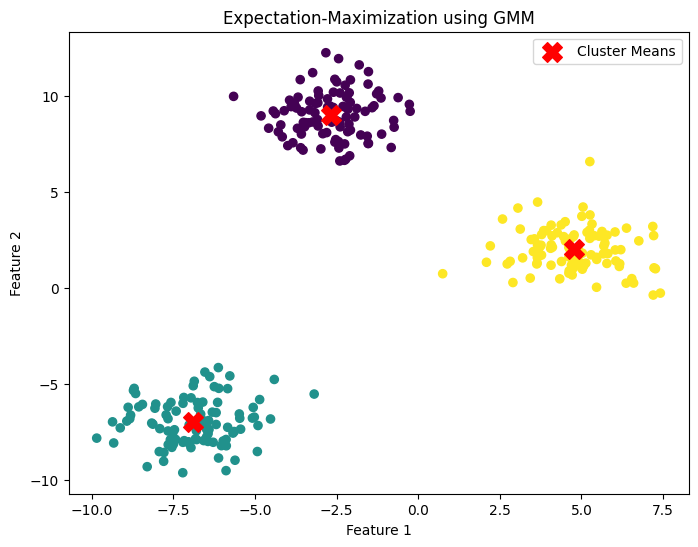

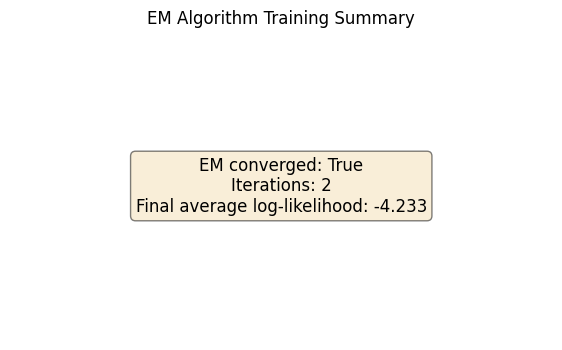

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

# Generate sample dataset
X, _ = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.2,
    random_state=42
)

# Create Gaussian Mixture Model
model = GaussianMixture(
    n_components=3,
    random_state=42,
    n_init=5
)

# EM training
model.fit(X)

# Cluster prediction
labels = model.predict(X)

print("EM Algorithm: Gaussian Mixture Model")
print("Number of clusters:", model.n_components)
print("Converged:", model.converged_)
print("Number of iterations:", model.n_iter_)
print("Means of clusters:\n", model.means_)

# Graph 1: Cluster visualization
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=35)
plt.scatter(
    model.means_[:, 0], model.means_[:, 1],
    marker="X", s=200, color="red", label="Cluster Means"
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Expectation-Maximization using GMM")
plt.legend()
plt.show()

# Graph 2: Training summary
plt.figure(figsize=(7, 4))
plt.text(
    0.5, 0.5,
    f"EM converged: {model.converged_}\n"
    f"Iterations: {model.n_iter_}\n"
    f"Final average log-likelihood: {model.lower_bound_:.3f}",
    ha="center", va="center", fontsize=12,
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5)
)
plt.title("EM Algorithm Training Summary")
plt.axis("off")
plt.show()